# Hybrid power-plant scheduler: one file

**Where to put this file:** in the `3-tva-plant-scheduling` folder, next to `check.py` and the `data` folder (the same place as `starter.ipynb`).

**Kernel:** qBraid-SDK. No pandas needed.

**Run All is safe.** Nothing is sent to IonQ unless you change `TARGET` in section 6. Run All takes about 2 minutes.

| Section | What it does |
|---|---|
| 1 | Loads the data, solves MILP, runs the cheapest-first rule, QAOA alone and random guesses |
| 2 | Defines the hybrid (look-ahead hint + warm-start QAOA + filter + look-ahead pick) |
| 3 | Runs the normal hybrid for the day |
| 4 | Runs the lower-cost circuits for the day: reordered gates (13 layers to 7) and 5 qubits (28 gates to 10) |
| 5 | Draws the four slide-style graphs and saves them as PNG files |
| 6 | Runs one hour on a simulator or on IonQ hardware, for the normal circuit **and** the lower-gate circuits |
| 7 | Shows what came back for each circuit and saves the graph |
| 8 | Optional, slow (about 6 minutes): QAOA alone vs hybrid vs 35-CNOT hybrid with simulated noise. Off unless `RUN_CNOT = True` |
| 9 | The whole 24-hour day on a simulator or on IonQ hardware (24 jobs). Uses the local simulator unless you change `DAY_TARGET` |


## 1. Setup and baselines (MILP, cheapest-first rule, QAOA alone, random)

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.
plant     type                              pmin  pmax   $/MWh  no-load $/h  startup $  min up  min down
COAL      coal steam                         140   350   21.69          546     36,750     24h       48h
GAS_CC    gas combined cycle                 168   350   26.84          206     27,650      8h        5h
PEAKER_A  gas combustion turbine              20    50   28.89          443      5,150      3h        3h
PEAKER_B  gas combustion turbine (older)      20    50   39.51          749      5,150      3h        3h
OIL       oil combustion turbine              20    50  101.02          694        130      1h        1h


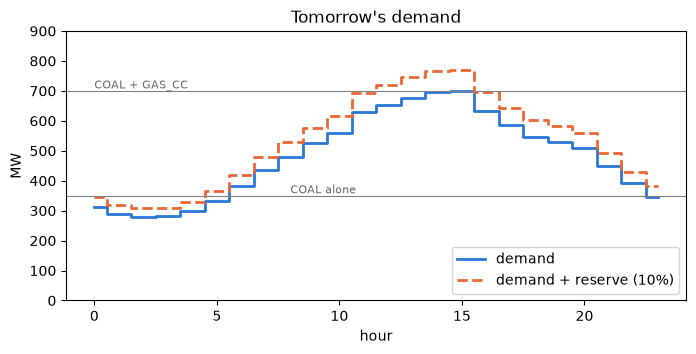

Total cost: $42,144  (startups $0, no-load $3,276, energy $38,868)
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
     5  -          reserve not met  capacity 350 MW < demand + reserve 364 MW
MILP solved in 0.041 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


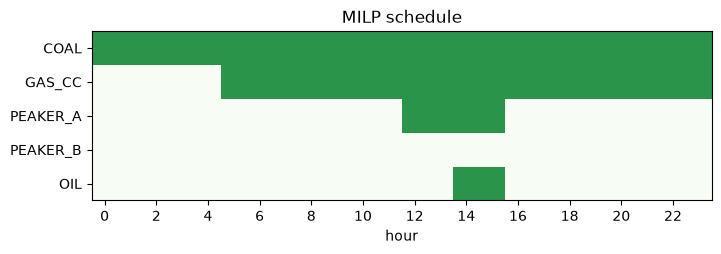

Total cost: $330,594  (startups $37,950, no-load $20,288, energy $272,356)
MILP optimum: $327,924   gap: +0.81%
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
    16  PEAKER_B   min up broken    turned off after 2 h on (needs 3)


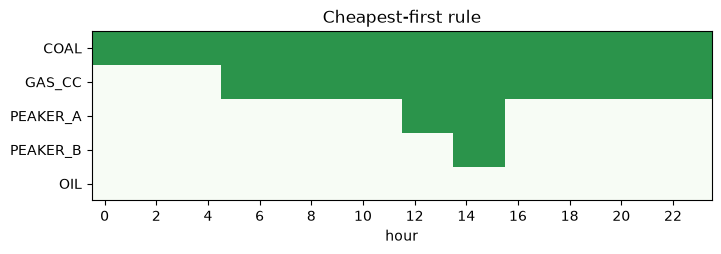

Cheapest QUBO bitstring: plants [1 1 0 0 1], slack [0 0 0], energy 4,028
Your choice: COAL+GAS_CC+OIL  ->  valid, cost $18,810
Match!
(The MILP picked COAL+GAS_CC+PEAKER_A for this hour.)
Your QUBO's cheapest answer matches the brute-force best in 24 of 24 hours.
QAOA for hour 12: 0.24 s, angles [ 0.638 -0.655]


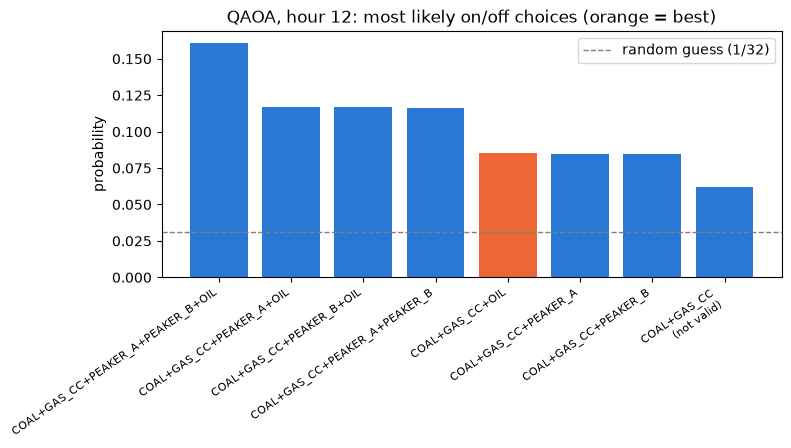

P(best choice) = 0.085   random guess = 0.031
QAOA for 24 hours: 1.6 s

Total cost: $351,082  (startups $43,360, no-load $26,163, energy $281,559)
MILP optimum: $327,924   gap: +7.06%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

hour  choice                       best for this hour?  P(best)  valid samples
   0  COAL                                         yes    0.049           70%
   1  COAL                                         yes    0.049           70%
   2  COAL                                         yes    0.049           70%
   3  COAL                                         yes    0.049           66%
   4  COAL                                         yes    0.049           66%
   5  COAL+OIL                                     yes    0.042           60%
   6  COAL+PEAKER_A+OIL                            yes    0.034           46%
   7  COAL+PEAKER_A+PEAKER_B+OIL                   yes    0.048           30%
   8  COAL+GAS_CC+PEAKER_A+PEAKER_B  

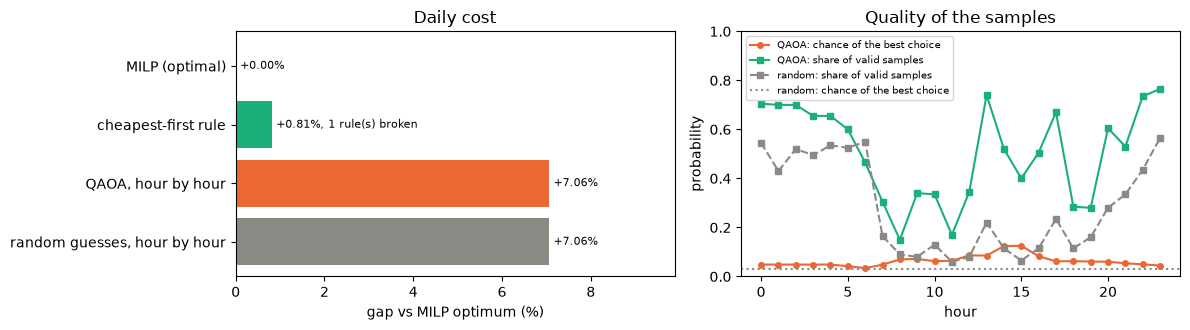

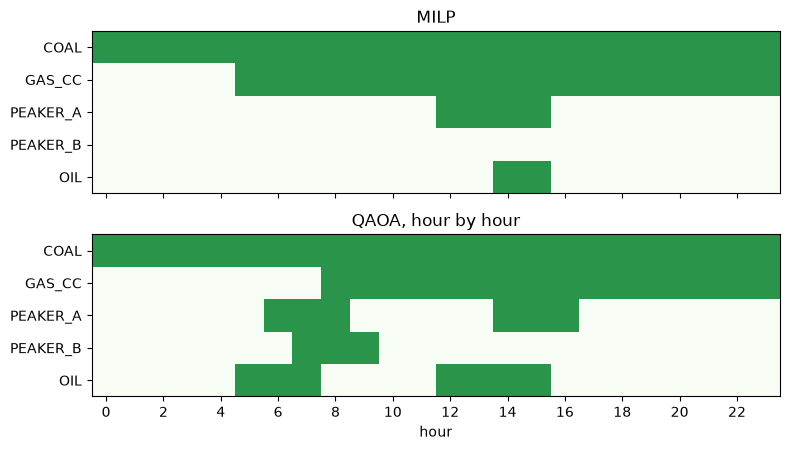

In [1]:
# Installs Qiskit Aer (the local simulator) the first time, if the kernel does not have it yet
import importlib.util, subprocess, sys
if importlib.util.find_spec("qiskit_aer") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "qiskit-aer"])
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

print(f"{'plant':<10}{'type':<32}{'pmin':>6}{'pmax':>6}{'$/MWh':>8}{'no-load $/h':>13}"
      f"{'startup $':>11}{'min up':>8}{'min down':>10}")
for p in plants:
    print(f"{p['plant_id']:<10}{p['type']:<32}{p['pmin_mw']:>6.0f}{p['pmax_mw']:>6.0f}"
          f"{p['marginal_cost_per_mwh']:>8.2f}{p['no_load_cost_per_h']:>13,.0f}"
          f"{p['startup_cost']:>11,.0f}{p['min_up_h']:>7.0f}h{p['min_down_h']:>9.0f}h")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(hours, demand, where="mid", color=COLORS["milp"], lw=2, label="demand")
ax.step(hours, demand + reserve, where="mid", color=COLORS["qaoa"], lw=2, ls="--",
        label="demand + reserve (10%)")
for level, text, x in [(350, "COAL alone", 8), (700, "COAL + GAS_CC", 0)]:
    ax.axhline(level, color="gray", lw=0.8)
    ax.text(x, level + 8, text, color="dimgray", fontsize=8)
ax.set(xlabel="hour", ylabel="MW", title="Tomorrow's demand", ylim=(0, 900))
ax.legend(loc="lower right")
plt.show()

#               COAL  GAS_CC  PEAKER_A  PEAKER_B  OIL
my_schedule = [[1,    0,      0,        0,        0],   # hour 0
               [1,    0,      0,        0,        0],   # hour 1
               [1,    0,      0,        0,        0],   # hour 2
               [1,    0,      0,        0,        0],   # hour 3
               [1,    0,      0,        0,        0],   # hour 4
               [1,    0,      0,        0,        0]]   # hour 5

hand_result = check_schedule(plants, demand[:6], reserve[:6], my_schedule)

milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

def cheapest_first(plants, demand, reserve):
    # Returns a (hours x plants) array of 0/1.
    schedule = np.zeros((len(demand), len(plants)), dtype=int)
    # TODO 1: rank the plants, then fill each hour (see the hints above).
    full_cost = np.array([p["marginal_cost_per_mwh"] + p["no_load_cost_per_h"] / p["pmax_mw"]
                          for p in plants])
    order = np.argsort(full_cost)                     # cheapest plant index first
    pmax = np.array([p["pmax_mw"] for p in plants])
    for t in range(len(demand)):
        need = demand[t] + reserve[t]
        capacity = 0.0
        for i in order:                               # switch plants on down the list...
            if capacity >= need:                      # ...until capacity covers demand + reserve
                break
            schedule[t, i] = 1
            capacity += pmax[i]
    return schedule


rule_schedule = cheapest_first(plants, demand, reserve)
rule_result = check_schedule(plants, demand, reserve, rule_schedule, milp_cost=milp_cost)
plot_schedule(rule_schedule, "Cheapest-first rule")
plt.show()

def plant_hour_costs(plants, was_on):
    # c[i] = approximate cost in $ of having plant i on for this hour.
    c = np.zeros(len(plants))
    # TODO 2: fill c[i] with the formula above.
    marginal_cheapest = min(p["marginal_cost_per_mwh"] for p in plants)
    for i, p in enumerate(plants):
        startup = p["startup_cost"] * (1 - was_on[i])          # only paid if it was off last hour
        no_load = p["no_load_cost_per_h"]                      # paid every hour it's on
        extra = p["pmin_mw"] * (p["marginal_cost_per_mwh"] - marginal_cheapest)  # forced pmin MW, priced vs cheapest
        c[i] = startup + no_load + extra
    return c

BLOCK_MW = 50               # capacity is counted in 50 MW blocks
N_SLACK = 3                 # slack bits: spare capacity = s0 + 2*s1 + 4*s2 blocks
N_QUBITS = N + N_SLACK      # qubits 0..4 = plants, 5..7 = slack


def build_qubo(plants, demand_mw, reserve_mw, was_on, penalty=None):
    # QUBO for one hour. Returns (Q, offset).
    c = plant_hour_costs(plants, was_on)
    A = 2 * c.max() if penalty is None else penalty
    b = np.array([p["pmax_mw"] / BLOCK_MW for p in plants] + [-(2 ** k) for k in range(N_SLACK)])
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)       # blocks needed this hour
    Q = np.zeros((N_QUBITS, N_QUBITS))
    offset = 0.0
    # TODO 3: add the cost part and the penalty part to Q and offset.
# 1) Cost part: each plant's hourly cost sits on its own diagonal entry.
    for i in range(N):
        Q[i, i] += c[i]
    # 2) Penalty part: A * (sum_j b_j y_j - r)^2, expanded using y_j^2 = y_j.
    for j in range(N_QUBITS):
        Q[j, j] += A * (b[j] ** 2 - 2 * r * b[j])          # single terms-> diagonal
        for k in range(j + 1, N_QUBITS):
            Q[j, k] += A * 2 * b[j] * b[k]                  # pair terms -> upper triangle
    offset += A * r ** 2
    return Q, offset

# Bit j of an integer index = qubit j. Row k of INDEX_BITS holds the 8 bits of index k.
# (Qiskit prints bitstrings with qubit 0 as the LAST character. Using integer indices
#  everywhere means you never have to reverse a string.)
INDEX_BITS = (np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1
PLANT_INDEX = INDEX_BITS[:, :N] @ (2 ** np.arange(N))   # on/off choice (0..31) inside each index


def all_energies(Q, offset):
    # QUBO energy of all 256 bitstrings.
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", INDEX_BITS, U, INDEX_BITS) + offset


def brute_force_qubo(Q, offset):
    E = all_energies(Q, offset)
    k = int(np.argmin(E))
    return INDEX_BITS[k], E[k]


def label(choice):
    # Plant names for an on/off choice given as a 0..31 index or a list of 0/1.
    on = [(choice >> i) & 1 for i in range(N)] if np.isscalar(choice) else choice
    return "+".join(n for n, u in zip(names, on) if u) or "none"

TEST_HOUR = 12
was_on = milp_schedule[TEST_HOUR - 1]        # who was on the hour before (from the MILP)
Q, offset = build_qubo(plants, demand[TEST_HOUR], reserve[TEST_HOUR], was_on)
bits, energy = brute_force_qubo(Q, offset)
print(f"Cheapest QUBO bitstring: plants {bits[:N]}, slack {bits[N:]}, energy {energy:,.0f}")
check_hour(plants, demand[TEST_HOUR], reserve[TEST_HOUR], bits[:N], was_on=was_on)
print("(The MILP picked", label(list(milp_schedule[TEST_HOUR])), "for this hour.)")

# Every hour at once, with the MILP's previous hour as "who was on".
start_state = [int(p["on_at_start"]) for p in plants]
matches = 0
for t in hours:
    was = milp_schedule[t - 1] if t > 0 else start_state
    Qt, off_t = build_qubo(plants, demand[t], reserve[t], was)
    bits_t, _ = brute_force_qubo(Qt, off_t)
    matches += check_hour(plants, demand[t], reserve[t], bits_t[:N], was_on=was, verbose=False)["matches_best"]
print(f"Your QUBO's cheapest answer matches the brute-force best in {matches} of {len(hours)} hours.")

def qubo_to_ising(Q):
    # y = (1 - z) / 2 turns the QUBO into  sum_j h_j Z_j + sum_jk J_jk Z_j Z_k + constant.
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4
                h[j] -= Q[j, k] / 4
                h[k] -= Q[j, k] / 4
    return h, J


def qaoa_circuit(Q, p=1):
    # Parameterized QAOA circuit with p layers. Returns (circuit, parameters).
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))   # keeps angles in a sane range
    gammas, betas = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(len(Q))
    qc.h(range(len(Q)))
    for layer in range(p):
        for j, hj in enumerate(h):
            if hj != 0:
                qc.rz(2 * gammas[layer] * hj / scale, j)
        for (j, k), Jjk in J.items():
            qc.rzz(2 * gammas[layer] * Jjk / scale, j, k)
        qc.rx(2 * betas[layer], range(len(Q)))
    return qc, list(gammas) + list(betas)


def run_qaoa(Q, offset, p=1, start=None, maxiter=60):
    # Tune the angles on the exact statevector. Returns (angles, probabilities of all 256 bitstrings).
    E = all_energies(Q, offset)
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = qaoa_circuit(Q, p)

    def probs_at(angles):
        return Statevector(qc.assign_parameters(dict(zip(params, angles)))).probabilities()

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:     # coarse grid for one (gamma, beta), used in every layer
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, 1.5, 8)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


def choice_probs(probs):
    # Probability of each on/off choice (0..31), summed over the slack qubits.
    return np.bincount(PLANT_INDEX, weights=probs, minlength=2 ** N)

start = time.perf_counter()
angles, probs = run_qaoa(Q, offset, p=1)
print(f"QAOA for hour {TEST_HOUR}: {time.perf_counter() - start:.2f} s, angles {np.round(angles, 3)}")

pc = choice_probs(probs)
best_k = int(bits[:N] @ (2 ** np.arange(N)))          # brute-force best from above
top = np.argsort(-pc)[:8]
valid = [hour_ok(plants, demand[TEST_HOUR], reserve[TEST_HOUR], [(k >> i) & 1 for i in range(N)]) for k in top]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(top)), pc[top], color=[COLORS["qaoa"] if k == best_k else COLORS["milp"] for k in top])
ax.axhline(1 / 2 ** N, color="gray", ls="--", lw=1, label="random guess (1/32)")
ax.set_xticks(range(len(top)), [label(int(k)) + ("" if ok else "\n(not valid)") for k, ok in zip(top, valid)],
              rotation=35, ha="right", fontsize=8)
ax.set(ylabel="probability", title=f"QAOA, hour {TEST_HOUR}: most likely on/off choices (orange = best)")
ax.legend()
plt.show()
print(f"P(best choice) = {pc[best_k]:.3f}   random guess = {1 / 2 ** N:.3f}")

def add_locks(Q, offset, must_on, must_off, weight):
    # Penalty weight*(1 - x_i) for a plant that must stay on, weight*x_i for one that must stay off.
    Q = Q.copy()
    for i in must_on:
        Q[i, i] -= weight
        offset += weight
    for i in must_off:
        Q[i, i] += weight
    return Q, offset


def schedule_day(p=1, shots=200, sampler="qaoa", seed=7, penalty=None):
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], None
    was_on = [int(x["on_at_start"]) for x in plants]
    for t in hours:
        must_on, must_off = locks(plants, history)
        Q, offset = build_qubo(plants, demand[t], reserve[t], was_on, penalty=penalty)
        Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
        if sampler == "qaoa":
            angles, probs = run_qaoa(Q, offset, p=p, start=angles)
        else:                                   # random guessing, for comparison
            probs = np.full(2 ** N_QUBITS, 1 / 2 ** N_QUBITS)
        samples = rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())
        seen = [list(INDEX_BITS[k][:N]) for k in np.unique(PLANT_INDEX[samples])]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:                              # nothing fully valid: allow breaking a lock
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        if ok:
            pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
        else:                                   # still nothing: take the most common sample
            pick = list(INDEX_BITS[np.bincount(PLANT_INDEX[samples]).argmax()][:N])
        ref = check_hour(plants, demand[t], reserve[t], pick, was_on, must_on, must_off, verbose=False)
        best_k = None if ref["best_choice"] is None else int(np.dot(ref["best_choice"], 2 ** np.arange(N)))
        valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], INDEX_BITS[k][:N], must_on, must_off)
                               for k in samples])
        log.append(dict(hour=t, pick=pick, matches_best=ref["matches_best"], valid_share=valid_share,
                        p_best=0.0 if best_k is None else choice_probs(probs)[best_k],
                        Q=Q, offset=offset, angles=angles))
        history.append(pick)
        was_on = pick
    return np.array(history), log

start = time.perf_counter()
qaoa_schedule, qaoa_log = schedule_day(p=1, shots=200)
print(f"QAOA for 24 hours: {time.perf_counter() - start:.1f} s\n")
qaoa_result = check_schedule(plants, demand, reserve, qaoa_schedule, milp_cost=milp_cost)

print(f"\n{'hour':>4}  {'choice':<28}{'best for this hour?':>20}{'P(best)':>9}{'valid samples':>15}")
for row in qaoa_log:
    print(f"{row['hour']:>4}  {label(row['pick']):<28}{'yes' if row['matches_best'] else 'no':>20}"
          f"{row['p_best']:>9.3f}{row['valid_share']:>14.0%}")

random_schedule, random_log = schedule_day(sampler="random")
random_result = check_schedule(plants, demand, reserve, random_schedule, milp_cost=milp_cost, verbose=False)

results = {"MILP (optimal)": (milp_result, COLORS["milp"]),
           "cheapest-first rule": (rule_result, COLORS["rule"]),
           "QAOA, hour by hour": (qaoa_result, COLORS["qaoa"]),
           "random guesses, hour by hour": (random_result, COLORS["random"])}
print(f"{'method':<30}{'daily cost $':>14}{'gap':>10}{'rules broken':>14}")
for name, (r, _) in results.items():
    print(f"{name:<30}{r['total_cost']:>14,.0f}{r['gap_pct']:>+9.2f}%{len(r['violations']):>14}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].barh(list(results), [r["gap_pct"] for r, _ in results.values()],
             color=[color for _, color in results.values()])
for y, (r, _) in enumerate(results.values()):
    broken = f", {len(r['violations'])} rule(s) broken" if r["violations"] else ""
    axes[0].text(max(r["gap_pct"], 0) + 0.1, y, f"{r['gap_pct']:+.2f}%{broken}", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.4 * max(max(r["gap_pct"] for r, _ in results.values()), 1))
axes[0].set(xlabel="gap vs MILP optimum (%)", title="Daily cost")
axes[1].plot(hours, [row["p_best"] for row in qaoa_log], "o-", color=COLORS["qaoa"], ms=4,
             label="QAOA: chance of the best choice")
axes[1].plot(hours, [row["valid_share"] for row in qaoa_log], "s-", color=COLORS["rule"], ms=4,
             label="QAOA: share of valid samples")
axes[1].plot(hours, [row["valid_share"] for row in random_log], "s--", color=COLORS["random"], ms=4,
             label="random: share of valid samples")
axes[1].axhline(1 / 2 ** N, color=COLORS["random"], ls=":", label="random: chance of the best choice")
axes[1].set(xlabel="hour", ylabel="probability", ylim=(0, 1), title="Quality of the samples")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
plot_schedule(milp_schedule, "MILP", ax=axes[0]).set_xlabel("")
plot_schedule(qaoa_schedule, "QAOA, hour by hour", ax=axes[1])
plt.tight_layout()
plt.show()



## 2. The hybrid scheduler (definitions only)

In [2]:
# ===== Hybrid scheduler: classical look-ahead + warm-start QAOA + classical look-ahead pick =====
# Paste below section 6 of starter.ipynb (it uses the notebook's own build_qubo, add_locks, run_qaoa, ...).
import check as _check
from qiskit.circuit import Parameter
from scipy.optimize import milp as _milp, Bounds as _Bounds


def _capture_day_model():
    """Borrow the whole-day model that check.solve_milp builds, so we can solve its LP relaxation."""
    box, orig = {}, _check.milp
    def grab(c, constraints=None, integrality=None, bounds=None, **kw):
        box.update(c=c, cons=constraints, ub=np.array(bounds.ub, float))
        return orig(c, constraints=constraints, integrality=integrality, bounds=bounds, **kw)
    _check.milp = grab
    try:
        solve_milp(plants, demand, reserve)
    finally:
        _check.milp = orig
    return box


DAY = _capture_day_model()
T_H = len(demand)
_look_cache, _tune_cache = {}, {}


def look_ahead(history, candidate=None):
    """Classical look-ahead. Fix the hours already decided (plus this hour's candidate, if given),
    let every later on/off choice be a fraction between 0 and 1, and solve that easy problem (an LP).
    Returns (lowest day cost still possible, how 'on' each plant wants to be in the next open hour)."""
    fixed = [list(h) for h in history] + ([list(candidate)] if candidate is not None else [])
    key = tuple(map(tuple, fixed))
    if key not in _look_cache:
        lb, ub = np.zeros(len(DAY["c"])), DAY["ub"].copy()
        for t, row in enumerate(fixed):
            for i, u in enumerate(row):
                lb[i * T_H + t] = ub[i * T_H + t] = u
        res = _milp(DAY["c"], constraints=DAY["cons"], integrality=np.zeros(len(lb)), bounds=_Bounds(lb, ub))
        t = len(fixed)
        if res.x is None:
            _look_cache[key] = (np.inf, None)
        else:
            _look_cache[key] = (res.fun, np.array([res.x[i * T_H + t] for i in range(N)]) if t < T_H else None)
    return _look_cache[key]


def warm_circuit(Q, hint, eps=0.25):
    """The notebook's QAOA circuit, but each plant qubit starts tilted toward the look-ahead hint.
    Same two-qubit gates as before; only one-qubit gates are added."""
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))
    lean = np.r_[np.clip(hint, eps, 1 - eps), np.full(N_SLACK, 0.5)]     # helper qubits start 50/50
    theta = 2 * np.arcsin(np.sqrt(lean))
    gamma, beta = Parameter("gamma"), Parameter("beta")
    qc = QuantumCircuit(len(Q))
    for j in range(len(Q)):
        qc.ry(theta[j], j)                                   # start near the hint
    for j, hj in enumerate(h):
        if hj != 0:
            qc.rz(2 * gamma * hj / scale, j)                 # cost layer (unchanged)
    for (j, k), Jjk in J.items():
        qc.rzz(2 * gamma * Jjk / scale, j, k)
    for j in range(len(Q)):                                  # mixer that keeps the hint as its home state
        qc.ry(-theta[j], j); qc.rz(-2 * beta, j); qc.ry(theta[j], j)
    return qc, [gamma, beta]


def run_warm(Q, offset, hint, eps=0.25, maxiter=60):
    E = all_energies(Q, offset); E = (E - E.min()) / (E.max() - E.min())
    qc, params = warm_circuit(Q, hint, eps)
    probs_at = lambda a: Statevector(qc.assign_parameters(dict(zip(params, a)))).probabilities()
    avg = lambda a: probs_at(a) @ E
    start = min(((g, b) for g in np.linspace(0.0, 3.0, 16) for b in np.linspace(-1.5, 1.5, 13)), key=avg)
    res = minimize(avg, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    best = res.x if res.fun <= avg(start) else np.array(start)
    return best, probs_at(best)


def schedule_day_hybrid(shots=20, sampler="warm", pick="look_ahead", seed=7, eps=0.25):
    """sampler: 'warm' (hint + QAOA), 'qaoa' (plain QAOA), 'lp_round' (hint + coin flips, no quantum), 'random'.
    pick: 'look_ahead' (lowest day cost still possible) or 'this_hour' (cheapest for this hour, as in section 5)."""
    rng = np.random.default_rng(seed)
    history, was_on = [], [int(x["on_at_start"]) for x in plants]
    for t in hours:
        must_on, must_off = locks(plants, history)
        _, hint = look_ahead(history)
        if hint is None:                                     # only after an earlier rule break
            hint = np.full(N, 0.5)
        if sampler in ("warm", "qaoa"):
            key = (sampler, int(t), tuple(was_on), tuple(must_on), tuple(must_off), tuple(np.round(hint, 3)), eps)
            if key not in _tune_cache:
                Q, offset = build_qubo(plants, demand[t], reserve[t], was_on)
                Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
                _tune_cache[key] = (run_warm(Q, offset, hint, eps) if sampler == "warm" else run_qaoa(Q, offset, p=1))[1]
            probs = _tune_cache[key]
            ks = PLANT_INDEX[rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())]
        elif sampler == "lp_round":
            ks = (rng.random((shots, N)) < np.clip(hint, eps, 1 - eps)) @ (2 ** np.arange(N))
        else:
            ks = rng.integers(0, 2 ** N, size=shots)
        seen = [[int(k >> i) & 1 for i in range(N)] for k in np.unique(ks)]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        this_hour = lambda c: hour_cost(plants, demand[t], c, was_on)
        if not ok:
            choice = [int(np.bincount(ks).argmax() >> i) & 1 for i in range(N)]
        elif pick == "look_ahead":
            bound, choice = min(((look_ahead(history, c)[0], c) for c in ok), key=lambda s: s[0])
            if not np.isfinite(bound):
                choice = min(ok, key=this_hour)
        else:
            choice = min(ok, key=this_hour)
        history.append(choice); was_on = choice
    return np.array(history)


## 3. Run the hybrid for the whole day

In [3]:
# ===== Run the hybrid and compare it with your current QAOA (about 2 minutes) =====
hybrid_schedule = schedule_day_hybrid(shots=20, sampler="warm", pick="look_ahead", seed=7)
print("Hybrid, 20 shots per hour:")
hybrid_result = check_schedule(plants, demand, reserve, hybrid_schedule, milp_cost=milp_cost)

Hybrid, 20 shots per hour:
Total cost: $329,264  (startups $33,060, no-load $20,666, energy $275,538)
MILP optimum: $327,924   gap: +0.41%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


## 4. Shallower circuit: reordered gates, and the 5-qubit option

In [4]:
# ===== Cell 7: hybrid with the commuting-gate tricks (shallower circuit) and the no-helper-qubit option =====
# Needs sections 1-6 and hybrid Cell 1.
from qiskit.quantum_info import Operator

def round_robin(n):
    """n-1 rounds; in each round every qubit is in exactly one pair, so a round runs in parallel.
    For an odd number of qubits one qubit sits out each round."""
    m = n + (n % 2)
    t, rounds = list(range(m)), []
    for _ in range(m - 1):
        rounds.append([tuple(sorted((t[i], t[m - 1 - i]))) for i in range(m // 2) if max(t[i], t[m - 1 - i]) < n])
        t = [t[0]] + [t[-1]] + t[1:-1]
    return rounds

def ising_terms(Q):
    """Same as the notebook's qubo_to_ising, but works for any number of qubits."""
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4; h[j] -= Q[j, k] / 4; h[k] -= Q[j, k] / 4
    return h, J

def warm_circuit_fast(Q, hint, eps=0.25, n_plants=None, parallel=True):
    """Warm-start QAOA circuit. parallel=True reorders the (commuting) RZZ gates into round-robin
    rounds and lets each qubit start its mixer as soon as its last RZZ is done. Same maths, less depth."""
    n = len(Q); n_plants = N if n_plants is None else n_plants
    h, J = ising_terms(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))
    lean = np.r_[np.clip(hint, eps, 1 - eps), np.full(n - n_plants, 0.5)]
    theta = 2 * np.arcsin(np.sqrt(lean))
    gamma, beta = Parameter("gamma"), Parameter("beta")
    qc = QuantumCircuit(n)
    def mixer(j):
        qc.ry(-theta[j], j); qc.rz(-2 * beta, j); qc.ry(theta[j], j)
    for j in range(n):
        qc.ry(theta[j], j)
        if h[j] != 0:
            qc.rz(2 * gamma * h[j] / scale, j)
    if not parallel:
        for (j, k), v in J.items():
            qc.rzz(2 * gamma * v / scale, j, k)
        for j in range(n):
            mixer(j)
        return qc, [gamma, beta]
    rounds = [[p for p in r if p in J] for r in round_robin(n)]
    last = {q: ri for ri, r in enumerate(rounds) for p in r for q in p}
    for ri, r in enumerate(rounds):
        for (j, k) in r:
            qc.rzz(2 * gamma * J[(j, k)] / scale, j, k)
        for q in range(n):
            if last.get(q) == ri:
                mixer(q)                                   # this qubit is finished with RZZ: mix now
    for q in range(n):
        if q not in last:
            mixer(q)
    return qc, [gamma, beta]

# ---- no-helper-qubit QUBO ("unbalanced penalization"): 5 qubits instead of 8 ----
UNBAL_L1, UNBAL_L2 = 0.10, 0.025        # the values your unbalanced.py search found (in units of max c)

def build_qubo_unbalanced(plants, demand_mw, reserve_mw, was_on, l1=UNBAL_L1, l2=UNBAL_L2):
    """E(x) = sum c_i x_i + cmax * ( -l1*g + l2*g^2 ),  g = (capacity blocks) - (blocks needed)."""
    c = plant_hour_costs(plants, was_on)
    a = np.array([p["pmax_mw"] / BLOCK_MW for p in plants])
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)
    Q, cm = np.zeros((N, N)), c.max()
    for i in range(N):
        Q[i, i] += c[i] + cm * (-l1 * a[i] + l2 * (a[i] ** 2 - 2 * r * a[i]))
        for k in range(i + 1, N):
            Q[i, k] += cm * l2 * 2 * a[i] * a[k]
    return Q, cm * (l1 * r + l2 * r ** 2)

_fast_cache = {}

def tune_any(Q, offset, hint, eps, n_plants, parallel=True, maxiter=60):
    n = len(Q)
    bits = (np.arange(2 ** n)[:, None] >> np.arange(n)) & 1
    E = np.einsum("bj,jk,bk->b", bits, np.triu(Q), bits) + offset
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = warm_circuit_fast(Q, hint, eps, n_plants, parallel)
    probs_at = lambda x: Statevector(qc.assign_parameters(dict(zip(params, x)))).probabilities()
    avg = lambda x: probs_at(x) @ E
    start = min(((g, b) for g in np.linspace(0.0, 3.0, 16) for b in np.linspace(-1.5, 1.5, 13)), key=avg)
    res = minimize(avg, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    best = res.x if res.fun <= avg(start) else np.array(start)
    return best, probs_at(best), qc.assign_parameters(dict(zip(params, best)))

def schedule_day_fast(shots=20, seed=7, encoding="slack", eps=0.25, return_circuits=False):
    """encoding='slack': your 8-qubit QUBO (5 plants + 3 helpers), gates reordered.
    encoding='unbalanced': 5 qubits, no helpers. Steps 1, 3 and 4 are unchanged."""
    rng = np.random.default_rng(seed)
    history, was_on, circuits = [], [int(x["on_at_start"]) for x in plants], []
    for t in hours:
        must_on, must_off = locks(plants, history)
        _, hint = look_ahead(history)
        if hint is None:
            hint = np.full(N, 0.5)
        key = (encoding, int(t), tuple(was_on), tuple(must_on), tuple(must_off), tuple(np.round(hint, 3)), eps)
        if key not in _fast_cache:
            build = build_qubo if encoding == "slack" else build_qubo_unbalanced
            Q, offset = build(plants, demand[t], reserve[t], was_on)
            Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
            _fast_cache[key] = tune_any(Q, offset, hint, eps, N)[1:]
        probs, qc = _fast_cache[key]
        circuits.append(qc)
        ks = rng.choice(len(probs), size=shots, p=probs / probs.sum()) & (2 ** N - 1)     # low 5 bits = plants
        seen = [[int(k >> i) & 1 for i in range(N)] for k in np.unique(ks)]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        this_hour = lambda c: hour_cost(plants, demand[t], c, was_on)
        if not ok:
            choice = [int(np.bincount(ks).argmax() >> i) & 1 for i in range(N)]
        else:
            bound, choice = min(((look_ahead(history, c)[0], c) for c in ok), key=lambda s: s[0])
            if not np.isfinite(bound):
                choice = min(ok, key=this_hour)
        history.append(choice); was_on = choice
    return (np.array(history), circuits) if return_circuits else np.array(history)

# ---- 1) proof the reordering changes nothing, and what it saves ----
_t = 14
_Q, _off = build_qubo(plants, demand[_t], reserve[_t], list(milp_schedule[_t - 1]))
_hint = np.array([0.9, 0.8, 0.6, 0.1, 0.3])
two_q = lambda c: c.depth(lambda g: g.operation.num_qubits == 2)
def circuit_stats(Q, n_plants, parallel):
    qc, params = warm_circuit_fast(Q, _hint, 0.25, n_plants, parallel)
    qc = qc.assign_parameters(dict(zip(params, [0.64, -0.66])))
    cx = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], optimization_level=3)
    return qc, qc.num_qubits, qc.count_ops().get("rzz", 0), two_q(qc), qc.depth(), cx.count_ops().get("cx", 0), two_q(cx)
_Qu, _ = build_qubo_unbalanced(plants, demand[_t], reserve[_t], list(milp_schedule[_t - 1]))
rows = [("Original order (8 qubits)", circuit_stats(_Q, N, False)),
        ("Reordered, early mixer (8 qubits)", circuit_stats(_Q, N, True)),
        ("No helper qubits + reordered (5)", circuit_stats(_Qu, N, True))]
print("Reordered circuit is mathematically identical:", Operator(rows[0][1][0]).equiv(Operator(rows[1][1][0])))
print(f"\n{'circuit':<36}{'qubits':>7}{'RZZ gates':>11}{'RZZ layers':>12}{'total depth':>13}{'CX gates':>10}{'CX layers':>11}")
for name, s in rows:
    print(f"{name:<36}{s[1]:>7}{s[2]:>11}{s[3]:>12}{s[4]:>13}{s[5]:>10}{s[6]:>11}")

# ---- 2) run the day both ways ----
fast_schedule = schedule_day_fast(shots=20, seed=7, encoding="slack")
print("\nHybrid, reordered 8-qubit circuit, 20 shots per hour:")
fast_result = check_schedule(plants, demand, reserve, fast_schedule, milp_cost=milp_cost)
unbal_schedule = schedule_day_fast(shots=20, seed=7, encoding="unbalanced")
print("\nHybrid, 5-qubit circuit (no helper qubits), 20 shots per hour:")
unbal_result = check_schedule(plants, demand, reserve, unbal_schedule, milp_cost=milp_cost)


Reordered circuit is mathematically identical: True

circuit                              qubits  RZZ gates  RZZ layers  total depth  CX gates  CX layers
Original order (8 qubits)                 8         28          13           18        56         26
Reordered, early mixer (8 qubits)         8         28           7           12        56         14
No helper qubits + reordered (5)          5         10           5           10        20         10

Hybrid, reordered 8-qubit circuit, 20 shots per hour:
Total cost: $329,264  (startups $33,060, no-load $20,666, energy $275,538)
MILP optimum: $327,924   gap: +0.41%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

Hybrid, 5-qubit circuit (no helper qubits), 20 shots per hour:
Total cost: $333,753  (startups $33,060, no-load $23,812, energy $276,881)
MILP optimum: $327,924   gap: +1.78%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


## 5. Slide-style graphs (saved as `slide_1` to `slide_4` PNG files)

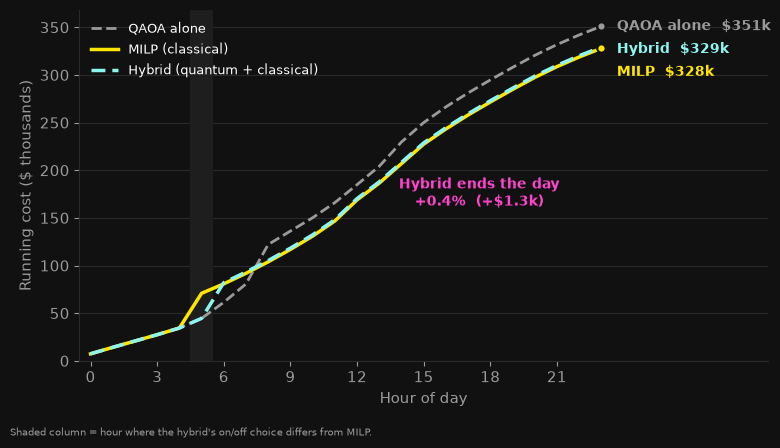

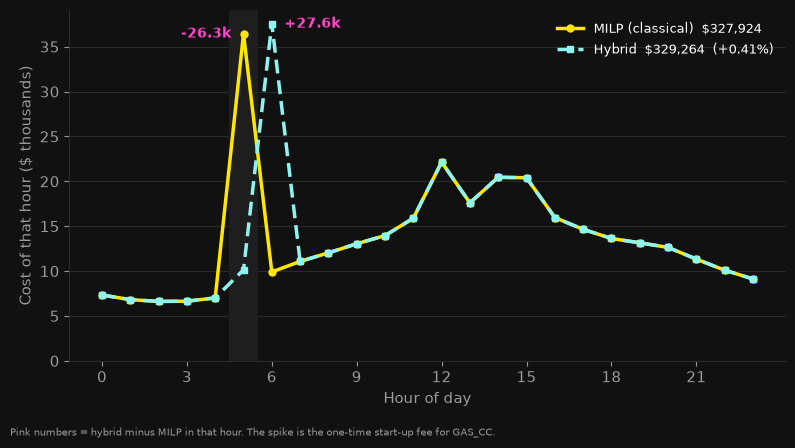

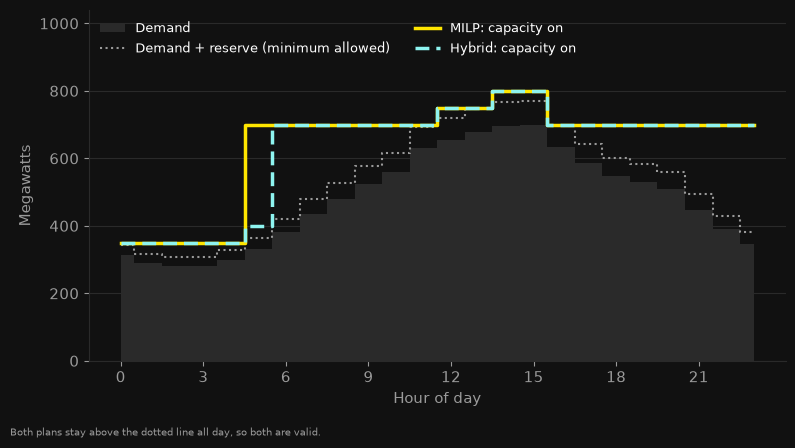

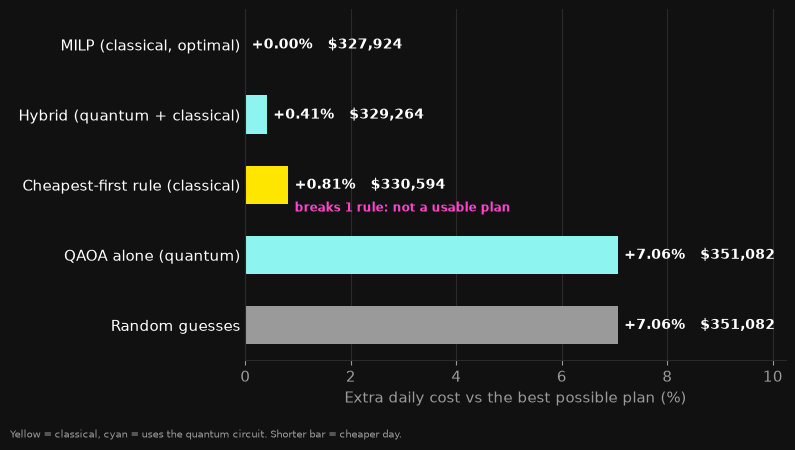

In [5]:
# ===== Cell 6: the graphs in the slide-deck style (dark background, yellow = classical, cyan = quantum) =====
# Needs sections 1-6, hybrid Cells 1-2, and ideally Cell 4 (simulator run). Saves 4 PNG files next to the notebook.
YELLOW, CYAN, PINK = "#FFE600", "#8EF4F0", "#FF44CC"
BG, PANEL, LINE, GRAY, WHITE = "#111111", "#1E1E1E", "#2A2A2A", "#9A9A9A", "#FFFFFF"
SLIDE = {"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": WHITE,
         "axes.edgecolor": LINE, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
         "grid.color": LINE, "axes.grid": True, "axes.axisbelow": True, "font.size": 11,
         "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False}

try:                                   # use the simulator run if Cell 4 was run, else the Cell 2 hybrid
    hyb_schedule, hyb_result, hyb_name = sim_schedule, sim_result, "Hybrid"
except NameError:
    hyb_schedule, hyb_result, hyb_name = hybrid_schedule, hybrid_result, "Hybrid"

def hourly_costs(schedule):
    was_on, out = [int(x["on_at_start"]) for x in plants], []
    for t in hours:
        out.append(hour_cost(plants, demand[t], list(schedule[t]), was_on)); was_on = list(schedule[t])
    return np.array(out)

H = np.arange(len(hours))
c_milp, c_qaoa, c_hyb = hourly_costs(milp_schedule), hourly_costs(qaoa_schedule), hourly_costs(hyb_schedule)
differs = lambda s: [t for t in H if list(s[t]) != list(milp_schedule[t])]

def finish(fig, ax, note, fname):
    ax.grid(axis="x", visible=False)
    fig.text(0.01, 0.012, note, color=GRAY, fontsize=7.5, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.045, 1, 1))
    fig.savefig(fname, dpi=200); plt.show()

with plt.rc_context(SLIDE):
    # ---- 1. Running cost through the day: MILP vs QAOA vs hybrid ----
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for t in differs(hyb_schedule):
        ax.axvspan(t - 0.5, t + 0.5, color=PANEL, lw=0)
    r_milp, r_qaoa, r_hyb = c_milp.cumsum() / 1000, c_qaoa.cumsum() / 1000, c_hyb.cumsum() / 1000
    ax.plot(H, r_qaoa, color=GRAY, lw=2, ls="--", label="QAOA alone")
    ax.plot(H, r_milp, color=YELLOW, lw=2.5, label="MILP (classical)")
    ax.plot(H, r_hyb, color=CYAN, lw=2.5, ls=(0, (4, 2)), label=f"{hyb_name} (quantum + classical)")
    ends = sorted([(r_qaoa, GRAY, "QAOA alone"), (r_hyb, CYAN, hyb_name), (r_milp, YELLOW, "MILP")], key=lambda e: -e[0][-1])
    y_label = np.inf
    for run, col, name in ends:                       # keep the end labels at least 24 apart so they never overlap
        y_label = min(run[-1], y_label - 24)
        ax.plot(H[-1], run[-1], "o", color=col, ms=6, mec=BG, mew=1.5)
        ax.text(H[-1] + 0.7, y_label, f"{name}  ${run[-1]:,.0f}k", color=col, fontsize=10, fontweight="bold", va="center")
    ax.annotate(f"{hyb_name} ends the day\n{hyb_result['gap_pct']:+.1f}%  (+${(c_hyb.sum() - c_milp.sum()) / 1000:,.1f}k)",
                (17, r_milp[17]), xytext=(17.5, r_milp[17] - 95), color=PINK, fontsize=10, fontweight="bold", ha="center")
    ax.set(xlabel="Hour of day", ylabel="Running cost ($ thousands)", xlim=(-0.5, H[-1] + 7.5), ylim=(0, None))
    ax.set_xticks(range(0, len(H), 3)); ax.legend(loc="upper left", fontsize=9.5)
    finish(fig, ax, "Shaded column = hour where the hybrid's on/off choice differs from MILP.", "slide_1_running_cost.png")

    # ---- 2. Cost of each hour: MILP vs hybrid ----
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for t in differs(hyb_schedule):
        ax.axvspan(t - 0.5, t + 0.5, color=PANEL, lw=0)
    ax.plot(H, c_milp / 1000, "o-", color=YELLOW, lw=2.5, ms=5, label=f"MILP (classical)  ${c_milp.sum():,.0f}")
    ax.plot(H, c_hyb / 1000, "s", color=CYAN, lw=2.5, ms=4, ls=(0, (4, 2)),
            label=f"{hyb_name}  ${c_hyb.sum():,.0f}  ({hyb_result['gap_pct']:+.2f}%)")
    for t in H:
        d = c_hyb[t] - c_milp[t]
        if abs(d) > 1:
            ax.annotate(f"{d / 1000:+,.1f}k", (t, max(c_hyb[t], c_milp[t]) / 1000), textcoords="offset points",
                        xytext=(-9, 0) if d < 0 else (9, 0), ha="right" if d < 0 else "left", va="center",
                        color=PINK, fontsize=10, fontweight="bold")
    ax.set(xlabel="Hour of day", ylabel="Cost of that hour ($ thousands)", ylim=(0, None))
    ax.set_xticks(range(0, len(H), 3)); ax.legend(loc="upper right", fontsize=9.5)
    finish(fig, ax, "Pink numbers = hybrid minus MILP in that hour. The spike is the one-time start-up fee for GAS_CC.",
           "slide_2_hourly_cost.png")

    # ---- 3. Capacity switched on vs what the grid needs ----
    fig, ax = plt.subplots(figsize=(8, 4.5))
    pmax = np.array([x["pmax_mw"] for x in plants])
    ax.fill_between(H, demand, step="mid", color=LINE, lw=0, label="Demand")
    ax.step(H, demand + reserve, where="mid", color=GRAY, lw=1.5, ls=":", label="Demand + reserve (minimum allowed)")
    ax.step(H, np.asarray(milp_schedule) @ pmax, where="mid", color=YELLOW, lw=2.5, label="MILP: capacity on")
    ax.step(H, np.asarray(hyb_schedule) @ pmax, where="mid", color=CYAN, lw=2.5, ls=(0, (4, 2)), label=f"{hyb_name}: capacity on")
    ax.set(xlabel="Hour of day", ylabel="Megawatts", ylim=(0, 1.3 * (np.asarray(milp_schedule) @ pmax).max()))
    ax.set_xticks(range(0, len(H), 3)); ax.legend(loc="upper left", fontsize=9, ncol=2)
    finish(fig, ax, "Both plans stay above the dotted line all day, so both are valid.", "slide_3_capacity.png")

    # ---- 4. Every method: extra cost over the best possible ----
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = [("MILP (classical, optimal)", milp_result, YELLOW), (f"{hyb_name} (quantum + classical)", hyb_result, CYAN),
            ("Cheapest-first rule (classical)", rule_result, YELLOW), ("QAOA alone (quantum)", qaoa_result, CYAN),
            ("Random guesses", random_result, GRAY)]
    ax.barh([b[0] for b in bars], [b[1]["gap_pct"] for b in bars], color=[b[2] for b in bars], height=0.55)
    for y, (_, r, _) in enumerate(bars):
        ax.text(r["gap_pct"] + 0.12, y, f"{r['gap_pct']:+.2f}%   ${r['total_cost']:,.0f}", va="center", color=WHITE,
                fontsize=10, fontweight="bold")
        if r["violations"]:
            ax.text(r["gap_pct"] + 0.12, y + 0.33, f"breaks {len(r['violations'])} rule: not a usable plan", va="center",
                    color=PINK, fontsize=8.5, fontweight="bold")
    ax.invert_yaxis(); ax.tick_params(axis="y", colors=WHITE, length=0)
    ax.set(xlabel="Extra daily cost vs the best possible plan (%)", xlim=(0, 1.45 * max(b[1]["gap_pct"] for b in bars)))
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    fig.text(0.01, 0.012, "Yellow = classical, cyan = uses the quantum circuit. Shorter bar = cheaper day.", color=GRAY,
             fontsize=7.5); fig.tight_layout(rect=(0, 0.045, 1, 1))
    fig.savefig("slide_4_all_methods.png", dpi=200); plt.show()


## 6. One hour on a simulator or on IonQ hardware: normal circuit and lower-gate circuits

`TARGET = "aer"` is free and instant. `"ionq_sim"` is free. **`"qpu"` uses credits: one paid job per circuit listed in `QPU_CIRCUITS` (2 by default). Run it once, copy the job IDs, then set `TARGET` back to `"aer"`.**

In [13]:
# ===== One hour of the hybrid on a simulator or on IonQ hardware: normal circuit AND lower-gate circuits =====
# TARGET = "aer"       local simulator, free, instant
# TARGET = "ionq_sim"  IonQ's simulator, Forte-1 noise, free
# TARGET = "qpu"       REAL hardware. USES CREDITS: one paid job per circuit in QPU_CIRCUITS. Run once.
TARGET = "qpu"  
HW_HOUR  = 14
HW_SHOTS = 100
QPU_ID   = "aws:ionq:qpu:forte-1"      # if it shows as unavailable try "aws:ionq:qpu:forte-1"
# "normal"     = the hybrid as first built: 8 qubits, 28 RZZ gates
# "reordered"  = same 28 gates packed into 7 layers
# "five_qubit" = no helper qubits: 5 qubits, 10 RZZ gates
SIM_CIRCUITS = ["normal", "reordered", "five_qubit"]     # simulators are free, so run all three
QPU_CIRCUITS = ["normal", "five_qubit"]                  # hardware: 2 paid jobs. Remove one to send only 1.

hw_history = [list(r) for r in hybrid_schedule[:HW_HOUR]]
hw_was_on = hw_history[-1] if hw_history else [int(x["on_at_start"]) for x in plants]
hw_must_on, hw_must_off = locks(plants, hw_history)
_, hw_hint = look_ahead(hw_history)

def hw_build(kind):
    """Returns (measured circuit, ideal probabilities of every bitstring)."""
    build = build_qubo_unbalanced if kind == "five_qubit" else build_qubo
    Q, offset = build(plants, demand[HW_HOUR], reserve[HW_HOUR], hw_was_on)
    Q, offset = add_locks(Q, offset, hw_must_on, hw_must_off, weight=2 * plant_hour_costs(plants, hw_was_on).max())
    _, ideal, bound = tune_any(Q, offset, hw_hint, 0.25, N, parallel=(kind != "normal"))
    qc = QuantumCircuit(len(Q), len(Q))
    qc.compose(bound, inplace=True)
    qc.measure(range(len(Q)), range(len(Q)))
    return transpile(qc, basis_gates=["rx", "ry", "rz", "rzz"]), ideal

hw_list = QPU_CIRCUITS if TARGET == "qpu" else SIM_CIRCUITS
if TARGET != "aer":
    from qbraid.runtime import QbraidProvider
    import warnings
    warnings.filterwarnings("ignore", message="Circuit contains measurement gates")
    hw_device = QbraidProvider().get_device("ionq:ionq:sim:simulator" if TARGET == "ionq_sim" else QPU_ID)
    print("Device:", hw_device.id, "| status:", hw_device.status())
    if TARGET == "qpu":
        assert HW_SHOTS <= 200, "keep hardware jobs at 200 shots or fewer"
        print(f"Sending {len(hw_list)} PAID job(s) to hardware: {hw_list}")
hw_device_id = "local Aer simulator" if TARGET == "aer" else hw_device.id

hw_runs, hw_jobs = {}, {}
for kind in hw_list:                                     # submit everything first, so job IDs print straight away
    qc, ideal = hw_build(kind)
    hw_runs[kind] = dict(qc=qc, ideal=ideal, rzz=qc.count_ops().get("rzz", 0),
                         layers=qc.depth(lambda g: g.operation.num_qubits == 2), job_id="none")
    print(f"{kind:<11} {qc.num_qubits} qubits, {hw_runs[kind]['rzz']} RZZ gates in {hw_runs[kind]['layers']} layers", end="")
    if TARGET == "aer":
        hw_runs[kind]["counts"] = AerSimulator().run(transpile(qc, AerSimulator()), shots=HW_SHOTS,
                                                     seed_simulator=11).result().get_counts()
        print()
    else:
        opts = {"runtime_options": {"noise_model": "forte-1"}} if TARGET == "ionq_sim" else {}
        hw_jobs[kind] = hw_device.run(qc, shots=HW_SHOTS, **opts)
        hw_runs[kind]["job_id"] = hw_jobs[kind].id
        print(f"   Job ID: {hw_jobs[kind].id}   <-- COPY THIS NOW")
for kind, job in hw_jobs.items():                        # then wait for the results (the QPU queue can be slow)
    hw_runs[kind]["counts"] = job.result().data.get_counts()
    print(f"{kind}: results received")


Device: aws:ionq:qpu:forte-1 | status: DeviceStatus.ONLINE
Sending 2 PAID job(s) to hardware: ['normal', 'five_qubit']
normal      8 qubits, 28 RZZ gates in 13 layers

line 1:2 no viable alternative at input 'pi'


   Job ID: aws:ionq:qpu:forte-1-9210-qjob-6af9583dc8f5265fb3f24e8c   <-- COPY THIS NOW
five_qubit  5 qubits, 10 RZZ gates in 5 layers

QuantumRuntimeServiceRequestError: Failed to create job: Failed to create job: Insufficient qBraid credits. Required: 830.00, Available: 20.00.

In [14]:
# Collect the hardware job that was already paid for. Submits nothing.
PAID_JOB_ID = "aws:ionq:qpu:forte-1-9210-qjob-6af9583dc8f5265fb3f24e8c"

try:
    paid_job = hw_jobs["normal"]                      # still in memory if the kernel wasn't restarted
except (NameError, KeyError):
    from qbraid.runtime import load_job
    paid_job = load_job(PAID_JOB_ID, provider="qbraid")

print("Job status:", paid_job.status())
paid_counts = paid_job.result().data.get_counts()     # waits here if the job is still in the queue
hw_runs = {"normal": {**hw_runs["normal"], "counts": paid_counts, "job_id": PAID_JOB_ID}}
hw_device_id = "aws:ionq:qpu:forte-1"
print("Results received:", sum(paid_counts.values()), "shots")
print("Most common:", dict(sorted(paid_counts.items(), key=lambda kv: -kv[1])[:5]))

Job status: JobStatus.QUEUED
Results received: 100 shots
Most common: {'00000111': 9, '00100111': 8, '01110111': 6, '00110111': 5, '00001111': 4}


## 7. What came back (safe to re-run; sends nothing)

In [8]:
# ===== What came back for each circuit, and what the hybrid does with it (safe to re-run; sends nothing) =====
YELLOW, CYAN, PINK, BG, LINE, GRAY, WHITE = "#FFE600", "#8EF4F0", "#FF44CC", "#111111", "#2A2A2A", "#9A9A9A", "#FFFFFF"
as_bits = lambda k: [(int(k) >> i) & 1 for i in range(N)]
hw_valid = np.array([hour_ok(plants, demand[HW_HOUR], reserve[HW_HOUR], as_bits(k), hw_must_on, hw_must_off) for k in range(2 ** N)])
milp_k = int(np.dot(milp_schedule[HW_HOUR], 2 ** np.arange(N)))

def plan_shares(counts):
    """Share of shots for each on/off plan (low 5 bits of the measured bitstring = the 5 plants)."""
    share, total = np.zeros(2 ** N), sum(counts.values())
    for key, c in counts.items():
        share[int(key.replace(" ", ""), 2) & (2 ** N - 1)] += c / total
    return share

print(f"Device: {hw_device_id} | hour {HW_HOUR} | {HW_SHOTS} shots | MILP's plan this hour: {label(milp_k)}\n")
print(f"{'circuit':<12}{'RZZ':>5}{'layers':>8}{'valid shots':>24}{'shots on MILP plan':>24}   hybrid's pick")
print(f"{'':<25}{'ideal -> this run':>24}{'ideal -> this run':>24}")
for kind, r in hw_runs.items():
    r["ideal_share"] = np.bincount(np.arange(len(r["ideal"])) & (2 ** N - 1), weights=r["ideal"], minlength=2 ** N)
    r["share"] = plan_shares(r["counts"])
    ok = [k for k in np.flatnonzero(r["share"] > 0) if hw_valid[k]]
    bounds = {k: look_ahead(hw_history, as_bits(k))[0] for k in ok}          # steps 3 and 4: filter, then look-ahead pick
    r["pick"] = min(bounds, key=bounds.get) if bounds else None
    pick = "no valid plan measured" if r["pick"] is None else label(r["pick"]) + ("  (= MILP)" if r["pick"] == milp_k else "  (differs from MILP)")
    v, m = f"{r['ideal_share'][hw_valid].sum():.0%} -> {r['share'][hw_valid].sum():.0%}", f"{r['ideal_share'][milp_k]:.1%} -> {r['share'][milp_k]:.1%}"
    print(f"{kind:<12}{r['rzz']:>5}{r['layers']:>8}{v:>24}{m:>24}   {pick}")
    print(f"{'':<12}job ID: {r['job_id']}")

with plt.rc_context({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": WHITE,
                     "axes.edgecolor": LINE, "axes.labelcolor": GRAY, "xtick.color": WHITE, "ytick.color": GRAY,
                     "grid.color": LINE, "axes.grid": True, "axes.axisbelow": True, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False}):
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.5), sharey=True)
    kinds, x = list(hw_runs), np.arange(len(hw_runs))
    ticks = [f"{k.replace('_', ' ')}\n{hw_runs[k]['rzz']} RZZ, {hw_runs[k]['layers']} layers" for k in kinds]
    for ax, title, pick in zip(axes, ["Valid shots", "Shots on MILP's plan"],
                               [lambda s: s[hw_valid].sum(), lambda s: s[milp_k]]):
        ideal, got = [pick(hw_runs[k]["ideal_share"]) for k in kinds], [pick(hw_runs[k]["share"]) for k in kinds]
        ax.bar(x - 0.2, ideal, 0.38, color=GRAY, label="Ideal (no noise)")
        ax.bar(x + 0.2, got, 0.38, color=CYAN, label="This run")
        for xi, (a, b) in enumerate(zip(ideal, got)):
            ax.text(xi - 0.2, a + 0.015, f"{a:.0%}", ha="center", color=WHITE, fontsize=9, fontweight="bold")
            ax.text(xi + 0.2, b + 0.015, f"{b:.0%}", ha="center", color=WHITE, fontsize=9, fontweight="bold")
        ax.set_title(title, color=WHITE, fontsize=11, fontweight="bold", loc="left")
        ax.set_xticks(x, ticks, fontsize=8); ax.tick_params(axis="x", length=0); ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    axes[0].set_ylabel("Share of the 200 shots"); axes[0].set_ylim(0, 1); axes[1].legend(loc="upper right", fontsize=9)
    fig.text(0.01, 0.012, f"Hybrid circuit, hour {HW_HOUR}, {HW_SHOTS} shots each, on {hw_device_id}.", color=GRAY, fontsize=7.5)
    fig.tight_layout(rect=(0, 0.045, 1, 1)); fig.savefig("slide_11_hardware_hour.png", dpi=200); plt.show()


Device: aws:ionq:qpu:forte-1 | hour 14 | 200 shots | MILP's plan this hour: COAL+GAS_CC+PEAKER_A+OIL

circuit       RZZ  layers             valid shots      shots on MILP plan   hybrid's pick
                                ideal -> this run       ideal -> this run


KeyError: 'counts'

## 8. Optional: the 35-CNOT version, compared under simulated noise

This rebuilds the cost layer as one shared CNOT network (56 CNOTs down to 35) and compares QAOA alone, the hybrid and the 35-CNOT hybrid, all at 200 shots per hour, with an **assumed** noise model. It is simulation only and is skipped unless `RUN_CNOT = True`.

In [ ]:
# ===== 35-CNOT hybrid vs hybrid vs QAOA alone, with simulated noise (local simulator, free) =====
RUN_CNOT = False      # set to True to run this section (about 6 minutes)
from qiskit.synthesis import synth_cnot_phase_aam
from qiskit.converters import circuit_to_dag
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import Operator

CX_BASIS = ["cx", "rz", "rx", "ry"]
# Assumed noise (NOT IonQ's model): error per CNOT, per one-qubit gate, per layer a qubit waits, per readout
NOISE = {"no noise": None,
         "typical noise": dict(p2=0.01, p1=0.0005, pidle=0.003, pro=0.005),
         "3x harsher noise": dict(p2=0.03, p1=0.0015, pidle=0.009, pro=0.015)}

def cost_layer_parity(h, J, scale, gamma, n):
    """The whole ZZ cost layer rebuilt as one CNOT 'parity network' (possible because all ZZ terms commute)."""
    pairs = list(J)
    table = [[1 if q in p else 0 for p in pairs] for q in range(n)]
    qc = QuantumCircuit(n)
    for j in range(n):
        if h[j] != 0:
            qc.rz(2 * gamma * h[j] / scale, j)
    qc.compose(synth_cnot_phase_aam(table, [float(2 * gamma * J[p] / scale) for p in pairs]), inplace=True)
    return qc

def build_circuit(kind, Q, hint, angles, eps=0.25):
    """kind: 'qaoa' (plain QAOA, 2 CNOTs per ZZ), 'hybrid' (warm start, 2 CNOTs per ZZ),
    'hybrid_cx' (warm start, parity-network cost layer). Returns the circuit in the CNOT basis."""
    n = len(Q); gamma, beta = angles
    if kind == "qaoa":
        beta = -beta          # the notebook's mixer is RX(2*beta); the mixer below equals RX(-2*beta) from a 50/50 start
    h, J = ising_terms(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))
    lean = np.full(n, 0.5) if kind == "qaoa" else np.r_[np.clip(hint, eps, 1 - eps), np.full(n - N, 0.5)]
    theta = 2 * np.arcsin(np.sqrt(lean))
    qc = QuantumCircuit(n)
    for j in range(n):
        qc.ry(theta[j], j)
    if kind == "hybrid_cx":
        qc.compose(cost_layer_parity(h, J, scale, gamma, n), inplace=True)
    else:
        for j in range(n):
            if h[j] != 0:
                qc.rz(2 * gamma * h[j] / scale, j)
        for (j, k), v in J.items():
            qc.rzz(2 * gamma * v / scale, j, k)
    for j in range(n):
        qc.ry(-theta[j], j); qc.rz(-2 * beta, j); qc.ry(theta[j], j)
    return transpile(qc, basis_gates=CX_BASIS, optimization_level=3 if kind == "hybrid_cx" else 1, seed_transpiler=1)

def _with_waits(qc):
    out = QuantumCircuit(qc.num_qubits)
    for layer in circuit_to_dag(qc).layers():
        ops, busy = layer["graph"].op_nodes(), set()
        for op in ops:
            qs = [qc.find_bit(q).index for q in op.qargs]; out.append(op.op, qs); busy.update(qs)
        if any(len(op.qargs) == 2 for op in ops):
            for q in set(range(qc.num_qubits)) - busy:
                out.id(q)                                  # this qubit waits during a CNOT layer
    return out

def noisy_probabilities(qc, p2, p1, pidle, pro):
    nm = NoiseModel(basis_gates=CX_BASIS + ["id"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["rx", "ry"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(pidle, 1), ["id"])
    c = _with_waits(qc); c.save_probabilities()
    sim = AerSimulator(method="density_matrix", noise_model=nm, basis_gates=CX_BASIS + ["id"])
    P = np.asarray(sim.run(transpile(c, sim, optimization_level=0)).result().data()["probabilities"])
    P, flip = P.reshape([2] * qc.num_qubits), np.array([[1 - pro, pro], [pro, 1 - pro]])
    for ax in range(qc.num_qubits):                        # readout error, qubit by qubit
        P = np.moveaxis(np.tensordot(flip, np.moveaxis(P, ax, 0), axes=1), 0, ax)
    return P.reshape(-1)

_cx_cache = {}
def _hour(kind, noise, t, was_on, must_on, must_off, hint, eps=0.25):
    key = (kind, noise, int(t), tuple(was_on), tuple(must_on), tuple(must_off), tuple(np.round(hint, 3)))
    if key not in _cx_cache:
        Q, offset = build_qubo(plants, demand[t], reserve[t], was_on)
        Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
        tkey = ("angles", "qaoa" if kind == "qaoa" else "warm") + key[2:]
        if tkey not in _cx_cache:                          # angles are tuned once, noise-free (as in section 7)
            _cx_cache[tkey] = run_qaoa(Q, offset, p=1)[0] if kind == "qaoa" else tune_any(Q, offset, hint, eps, N)[0]
        qc = build_circuit(kind, Q, hint, _cx_cache[tkey], eps)
        ideal = Statevector(qc).probabilities()
        probs = ideal if NOISE[noise] is None else noisy_probabilities(qc, **NOISE[noise])
        _cx_cache[key] = (probs, float(np.sum(np.sqrt(ideal * probs)) ** 2), qc.count_ops().get("cx", 0),
                          qc.depth(lambda g: g.operation.num_qubits == 2))
    return _cx_cache[key]

def day_with_noise(kind, noise="typical noise", shots=20, seed=7):
    """kind='qaoa' picks the cheapest valid plan for this hour (your section 5).
    'hybrid' / 'hybrid_cx' use the look-ahead hint and the look-ahead pick."""
    rng = np.random.default_rng(seed)
    history, was_on, info = [], [int(x["on_at_start"]) for x in plants], []
    for t in hours:
        must_on, must_off = locks(plants, history)
        hint = np.full(N, 0.5)
        if kind != "qaoa":
            _, hint = look_ahead(history)
            hint = np.full(N, 0.5) if hint is None else hint
        probs, match, n_cx, cx_layers = _hour(kind, noise, t, was_on, must_on, must_off, hint)
        info.append((match, n_cx, cx_layers))
        ks = rng.choice(len(probs), size=shots, p=probs / probs.sum()) & (2 ** N - 1)
        seen = [[int(k >> i) & 1 for i in range(N)] for k in np.unique(ks)]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)] \
             or [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        this_hour = lambda c: hour_cost(plants, demand[t], c, was_on)
        if not ok:
            choice = [int(np.bincount(ks).argmax() >> i) & 1 for i in range(N)]
        elif kind == "qaoa":
            choice = min(ok, key=this_hour)
        else:
            bound, choice = min(((look_ahead(history, c)[0], c) for c in ok), key=lambda s: s[0])
            if not np.isfinite(bound):
                choice = min(ok, key=this_hour)
        history.append(choice); was_on = choice
    return np.array(history), np.array(info).mean(0)


if RUN_CNOT:
    # ---- checks: plain-QAOA circuit reproduces the notebook's QAOA; gate-reduced circuit is the same calculation ----
    _Qc, _oc = build_qubo(plants, demand[14], reserve[14], list(milp_schedule[13]))
    _ang, _pr = run_qaoa(_Qc, _oc, p=1)
    print("QAOA-alone circuit matches the notebook's QAOA output:",
          bool(np.allclose(Statevector(build_circuit("qaoa", _Qc, None, _ang)).probabilities(), _pr, atol=1e-6)))
    _Q14, _ = build_qubo(plants, demand[14], reserve[14], list(milp_schedule[13]))
    _h14 = np.array([0.9, 0.8, 0.6, 0.1, 0.3])
    _a, _b = build_circuit("hybrid", _Q14, _h14, [0.64, -0.66]), build_circuit("hybrid_cx", _Q14, _h14, [0.64, -0.66])
    print("Gate-reduced circuit is mathematically identical to the hybrid circuit:", Operator(_a).equiv(Operator(_b)))

    KINDS = [("qaoa", "QAOA alone"), ("hybrid", "Hybrid"), ("hybrid_cx", "Gate-reduced hybrid")]
    CX_SHOTS, CX_SEEDS = 200, range(20)   # same shots for every method
    cx_table = {}
    print(f"\n{CX_SHOTS} shots per hour, {len(CX_SEEDS)} seeds.  Columns: valid days, mean gap vs MILP, match to noise-free output")
    print(f"{'method':<22}{'CNOTs':>7}{'layers':>8}" + "".join(f"{n:>30}" for n in NOISE))
    for kind, name in KINDS:
        line = ""
        for noise in NOISE:
            runs = [day_with_noise(kind, noise, CX_SHOTS, s) for s in CX_SEEDS]
            res = [check_schedule(plants, demand, reserve, r[0], milp_cost=milp_cost, verbose=False) for r in runs]
            gaps = [r["gap_pct"] for r in res if r["valid"]]
            info = np.mean([r[1] for r in runs], axis=0)
            cx_table[kind, noise] = dict(valid=len(gaps), gap=float(np.mean(gaps)) if gaps else np.nan, match=info[0],
                                         cx=info[1], layers=info[2])
            line += f"{f'{len(gaps)}/{len(res)}  {np.mean(gaps) if gaps else np.nan:+.2f}%  {info[0]:.3f}':>30}"
        print(f"{name:<22}{cx_table[kind, 'no noise']['cx']:>7.0f}{cx_table[kind, 'no noise']['layers']:>8.0f}" + line)

    # ===== Cell 10: slide-style graphs for Cell 9 (QAOA alone vs hybrid vs gate-reduced hybrid, with noise) =====
    YELLOW, CYAN, PINK = "#FFE600", "#8EF4F0", "#FF44CC"
    BG, PANEL, LINE, GRAY, WHITE = "#111111", "#1E1E1E", "#2A2A2A", "#9A9A9A", "#FFFFFF"
    SLIDE = {"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": WHITE,
             "axes.edgecolor": LINE, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
             "grid.color": LINE, "axes.grid": True, "axes.axisbelow": True, "font.size": 11,
             "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False}
    LINE_NOISE, LINE_SEED = "typical noise", 7

    def hourly_costs(schedule):
        was_on, out = [int(x["on_at_start"]) for x in plants], []
        for t in hours:
            out.append(hour_cost(plants, demand[t], list(schedule[t]), was_on)); was_on = list(schedule[t])
        return np.array(out)

    # one noisy day each, the SAME number of shots (CX_SHOTS) for all three
    n_qaoa = day_with_noise("qaoa", LINE_NOISE, CX_SHOTS, LINE_SEED)[0]
    n_hyb = day_with_noise("hybrid", LINE_NOISE, CX_SHOTS, LINE_SEED)[0]
    n_cx = day_with_noise("hybrid_cx", LINE_NOISE, CX_SHOTS, LINE_SEED)[0]
    res = {k: check_schedule(plants, demand, reserve, s, milp_cost=milp_cost, verbose=False)
           for k, s in [("qaoa", n_qaoa), ("hybrid", n_hyb), ("hybrid_cx", n_cx)]}
    for k, name in KINDS:
        print(f"{name:<22} ${res[k]['total_cost']:>9,.0f}  {res[k]['gap_pct']:+.2f}%  rules broken: {len(res[k]['violations'])}")
    print("The two hybrid schedules are identical:", bool((n_hyb == n_cx).all()))
    H = np.arange(len(hours))
    c = {"milp": hourly_costs(milp_schedule), "qaoa": hourly_costs(n_qaoa), "hybrid": hourly_costs(n_hyb), "hybrid_cx": hourly_costs(n_cx)}
    STYLE = [("qaoa", f"QAOA alone (56 CNOTs){'' if res['qaoa']['valid'] else ', breaks rules'}", GRAY, "--", 2),
             ("milp", "MILP (classical)", YELLOW, "-", 3),
             ("hybrid", "Hybrid (56 CNOTs)", CYAN, "-", 4.5),
             ("hybrid_cx", "Gate-reduced hybrid (35 CNOTs)", WHITE, (0, (2, 2)), 1.8)]

    def foot(fig, note, fname):
        fig.text(0.01, 0.012, note, color=GRAY, fontsize=7.5); fig.tight_layout(rect=(0, 0.045, 1, 1))
        fig.savefig(fname, dpi=200); plt.show()

    with plt.rc_context(SLIDE):
        # ---- 7. running cost through the day ----
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for k, name, col, ls, lw in STYLE:
            ax.plot(H, c[k].cumsum() / 1000, color=col, ls=ls, lw=lw, label=name)
        ends, y_label = sorted(STYLE, key=lambda s: -c[s[0]].sum()), np.inf
        for k, name, col, ls, lw in ends:
            y_label = min(c[k].sum() / 1000, y_label - 26)
            gap = "" if k == "milp" else f"  ({res[k]['gap_pct']:+.1f}%)"
            ax.text(H[-1] + 0.7, y_label, f"${c[k].sum() / 1000:,.0f}k{gap}", color=col, fontsize=10, fontweight="bold", va="center")
        ax.set(xlabel="Hour of day", ylabel="Running cost ($ thousands)", xlim=(-0.5, H[-1] + 6.5), ylim=(0, None))
        ax.set_xticks(range(0, len(H), 3)); ax.grid(axis="x", visible=False); ax.legend(loc="upper left", fontsize=9)
        foot(fig, f"All three: {CX_SHOTS} shots per hour, {LINE_NOISE} (assumed 1% error per CNOT). "
             + ("White dotted line sits on the cyan line: same schedule." if (n_hyb == n_cx).all() else ""),
             "slide_7_noisy_running_cost.png")

        # ---- 8. cost of each hour ----
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for k, name, col, ls, lw in STYLE:
            ax.plot(H, c[k] / 1000, color=col, ls=ls, lw=lw, marker="o" if k in ("milp", "qaoa") else None, ms=4, label=name)
        ax.set(xlabel="Hour of day", ylabel="Cost of that hour ($ thousands)", ylim=(0, None))
        ax.set_xticks(range(0, len(H), 3)); ax.grid(axis="x", visible=False); ax.legend(loc="upper right", fontsize=9)
        foot(fig, "Each spike is a plant start-up fee. QAOA alone starts and stops plants more often, so it has more spikes.",
             "slide_8_noisy_hourly_cost.png")

        # ---- 9. average result over 20 seeds, by noise level ----
        fig, ax = plt.subplots(figsize=(8, 4.5))
        x = np.arange(len(NOISE))
        for (k, name, col), dx in zip([("qaoa", "QAOA alone (56 CNOTs)", GRAY), ("hybrid", "Hybrid (56 CNOTs)", CYAN),
                                       ("hybrid_cx", "Gate-reduced hybrid (35 CNOTs)", WHITE)], (-0.27, 0, 0.27)):
            y = [0 if np.isnan(cx_table[k, n]["gap"]) else cx_table[k, n]["gap"] for n in NOISE]
            ax.bar(x + dx, y, 0.25, color=col, label=name)
            for xi, n, yi in zip(x, NOISE, y):
                e = cx_table[k, n]
                ax.text(xi + dx, yi + 0.15, f"{e['gap']:+.2f}%" if e["valid"] else "none\nvalid", ha="center", va="bottom",
                        color=WHITE, fontsize=9, fontweight="bold")
                ax.text(xi + dx, -0.2, f"{e['valid']}/{len(CX_SEEDS)}", ha="center", va="top",
                        color=PINK if e["valid"] < len(CX_SEEDS) else GRAY, fontsize=8)
        ax.set_xticks(x, [n.capitalize() for n in NOISE]); ax.tick_params(axis="x", length=0, pad=18, colors=WHITE)
        ax.set(ylabel="Mean extra daily cost vs MILP (%)"); ax.set_ylim(0, ax.get_ylim()[1] * 1.3); ax.grid(axis="x", visible=False)
        ax.legend(loc="upper center", fontsize=9, ncol=3, columnspacing=1.2, handlelength=1.2)
        foot(fig, f"All three: {CX_SHOTS} shots per hour, {len(CX_SEEDS)} seeds. Small numbers under bars = days (of {len(CX_SEEDS)}) with no rule broken.",
             "slide_9_noise_levels.png")

        # ---- 10. circuit size ----
        fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
        bar_names, cols = ["QAOA\nalone", "Hybrid", "Gate-reduced\nhybrid"], [GRAY, CYAN, WHITE]
        for ax, title, field in zip(axes, ["CNOT gates per hour", "CNOT layers (depth)"], ["cx", "layers"]):
            vals = [cx_table[k, "no noise"][field] for k, _ in KINDS]
            ax.bar(bar_names, vals, color=cols, width=0.6)
            for xi, v in enumerate(vals):
                ax.text(xi, v + max(vals) * 0.03, f"{v:.0f}", ha="center", color=WHITE, fontsize=13, fontweight="bold")
            ax.set_title(title, color=WHITE, fontsize=11, fontweight="bold", loc="left")
            ax.set_ylim(0, max(vals) * 1.2); ax.set_yticks([]); ax.grid(False)
            ax.spines["left"].set_visible(False); ax.tick_params(axis="x", length=0, labelsize=9, colors=WHITE)
        foot(fig, "Average over the 24 hourly circuits, after converting to CNOT gates. All three use 8 qubits.",
             "slide_10_cnot_savings.png")
else:
    print('Section 8 skipped. Set RUN_CNOT = True at the top of this cell to run it.')


## 9. The whole day (24 hours) on a simulator or on IonQ hardware

One job per hour, sent one after another, because each hour depends on the plan picked for the hour before. `DAY_TARGET = "aer"` is free and instant; `"ionq_sim"` is free; **`"qpu"` is 24 paid jobs.** Progress is saved after every hour, so if the cell stops you can run it again and it carries on from where it stopped without re-sending finished hours. When it finishes, re-run section 5 to redraw the slide graphs with this day.

In [ ]:
# ===== The WHOLE DAY (24 hours) of the hybrid on a simulator or on IonQ hardware =====
# DAY_TARGET = "aer"       local simulator, free, instant        <- default, so Run All never spends credits
# DAY_TARGET = "ionq_sim"  IonQ's simulator, Forte-1 noise, free (24 jobs)
# DAY_TARGET = "qpu"       REAL hardware: 24 PAID jobs, one per hour, sent one after another.
#                          Estimated cost at 50 shots: about 430 credits per hour, about 10,300 for the day.
DAY_TARGET  = "qpu"
DAY_METHOD  = "qaoa"
DAY_SHOTS   = 11
DAY_CIRCUIT = "reordered"
DAY_QPU_ID  = "aws:ionq:qpu:forte-1"
# Progress is saved to this file after every hour. If the cell stops for ANY reason (credits, queue, kernel),
# just run the cell again: finished hours are read from the file and are NOT sent or paid for again.
DAY_FILE    = f"hw_day_{DAY_TARGET}_{DAY_CIRCUIT}_{DAY_SHOTS}shots.json"

import json, os
day_meta = {"target": DAY_TARGET, "circuit": DAY_CIRCUIT, "shots": DAY_SHOTS}
day_saved = {"meta": day_meta, "hours": {}}
if os.path.exists(DAY_FILE):
    day_saved = json.load(open(DAY_FILE))
    assert day_saved["meta"] == day_meta, f"{DAY_FILE} was made with different settings; rename or delete it first"
def _save_day():
    json.dump(day_saved, open(DAY_FILE, "w"), indent=1)

if DAY_TARGET != "aer":
    from qbraid.runtime import QbraidProvider
    import warnings
    warnings.filterwarnings("ignore", message="Circuit contains measurement gates")
    day_device = QbraidProvider().get_device("ionq:ionq:sim:simulator" if DAY_TARGET == "ionq_sim" else DAY_QPU_ID)
    print("Device:", day_device.id, "| status:", day_device.status())
day_device_id = "local Aer simulator" if DAY_TARGET == "aer" else day_device.id
as_bits = lambda k: [(int(k) >> i) & 1 for i in range(N)]

def _counts_for_hour(t, qc):
    """Counts for hour t: from the progress file if already done, else from the device (saving as we go)."""
    rec = day_saved["hours"].setdefault(str(t), {})
    if "counts" in rec:
        return rec["counts"], "saved"
    if DAY_TARGET == "aer":
        rec["job_id"] = "none"
        rec["counts"] = AerSimulator().run(transpile(qc, AerSimulator()), shots=DAY_SHOTS, seed_simulator=100 + t).result().get_counts()
    else:
        if "job_id" in rec:                         # sent earlier but the cell stopped while waiting: fetch, don't resend
            from qbraid.runtime import load_job
            job = load_job(rec["job_id"], provider="qbraid")
        else:
            opts = {"runtime_options": {"noise_model": "forte-1"}} if DAY_TARGET == "ionq_sim" else {}
            job = day_device.run(qc, shots=DAY_SHOTS, **opts)
            rec["job_id"] = job.id
            _save_day()                             # job ID is on disk before we start waiting
        rec["counts"] = {str(k): int(v) for k, v in job.result().data.get_counts().items()}
    _save_day()
    return rec["counts"], "new"

day_history, day_was_on, day_rows, day_stopped = [], [int(x["on_at_start"]) for x in plants], [], None
print(f"{'hour':>4}  {'job':<6}{'valid shots':>12}{'plans seen':>12}   pick")
for t in hours:
    t = int(t)
    must_on, must_off = locks(plants, day_history)
    _, hint = look_ahead(day_history)                                           # step 1 (classical)
    hint = np.full(N, 0.5) if hint is None else hint
    build = build_qubo_unbalanced if DAY_CIRCUIT == "five_qubit" else build_qubo
    Q, offset = build(plants, demand[t], reserve[t], day_was_on)
    Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, day_was_on).max())
    _, ideal, bound = tune_any(Q, offset, hint, 0.25, N, parallel=(DAY_CIRCUIT != "normal"))
    qc = QuantumCircuit(len(Q), len(Q)); qc.compose(bound, inplace=True); qc.measure(range(len(Q)), range(len(Q)))
    qc = transpile(qc, basis_gates=["rx", "ry", "rz", "rzz"])
    try:
        counts, how = _counts_for_hour(t, qc)                                   # step 2 (quantum)
    except Exception as err:
        day_stopped = (t, err)
        break
    ks = np.array([int(key.replace(" ", ""), 2) & (2 ** N - 1) for key, c in counts.items() for _ in range(c)])
    seen = [as_bits(k) for k in np.unique(ks)]
    ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)] \
         or [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]      # step 3 (classical filter)
    valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], as_bits(k), must_on, must_off) for k in ks])
    if not ok:
        choice = as_bits(np.bincount(ks).argmax())
    else:                                                                       # step 4 (classical look-ahead pick)
        bound_cost, choice = min(((look_ahead(day_history, c)[0], c) for c in ok), key=lambda s: s[0])
        if not np.isfinite(bound_cost):
            choice = min(ok, key=lambda c: hour_cost(plants, demand[t], c, day_was_on))
    ideal_share = np.bincount(np.arange(len(ideal)) & (2 ** N - 1), weights=ideal, minlength=2 ** N)
    valid_mask = np.array([hour_ok(plants, demand[t], reserve[t], as_bits(k), must_on, must_off) for k in range(2 ** N)])
    milp_k = int(np.dot(milp_schedule[t], 2 ** np.arange(N)))
    day_rows.append(dict(hour=t, job_id=day_saved["hours"][str(t)]["job_id"], valid_share=float(valid_share),
                         ideal_valid=float(ideal_share[valid_mask].sum()), ideal_milp=float(ideal_share[milp_k]),
                         run_milp=float(np.mean(ks == milp_k)), milp_k=milp_k,
                         pick_k=int(np.dot(choice, 2 ** np.arange(N)))))
    print(f"{t:>4}  {how:<6}{valid_share:>12.0%}{len(seen):>12}   {label(int(np.dot(choice, 2 ** np.arange(N))))}")
    day_history.append(choice); day_was_on = choice

if day_stopped:
    print(f"\nSTOPPED at hour {day_stopped[0]}: {day_stopped[1]}")
    print(f"Hours 0 to {day_stopped[0] - 1} are saved in {DAY_FILE}. Fix the cause, then run this cell again: it resumes at hour {day_stopped[0]}.")
else:
    hw_day_schedule = np.array(day_history)
    print(f"\nHybrid, whole day on {day_device_id}, {DAY_SHOTS} shots per hour, circuit '{DAY_CIRCUIT}':")
    hw_day_result = check_schedule(plants, demand, reserve, hw_day_schedule, milp_cost=milp_cost)
    print(f"Average valid shots per hour: {np.mean([r['valid_share'] for r in day_rows]):.0%}")
    print(f"Job IDs are in {DAY_FILE}")
    sim_schedule, sim_result = hw_day_schedule, hw_day_result     # re-run section 5 to redraw slide_1..4 with this day


### 9b. The whole day, printed and as a graph (safe to re-run; sends nothing)

One row and one pair of bars per hour: gray is the exact noise-free result, cyan is what the device returned. If section 9 stopped partway, this shows the hours finished so far. Saves `slide_12_whole_day_shots.png`.

In [ ]:
# ===== Section 9 results, printed and as a graph (safe to re-run; sends nothing) =====
YELLOW, CYAN, PINK, BG, LINE, GRAY, WHITE = "#FFE600", "#8EF4F0", "#FF44CC", "#111111", "#2A2A2A", "#9A9A9A", "#FFFFFF"
done = len(day_rows)
print(f"Device: {day_device_id} | circuit '{DAY_CIRCUIT}' | {DAY_SHOTS} shots per hour | hours finished: {done} of {len(hours)}\n")
print(f"{'hour':>4}{'valid shots':>22}{'shots on MILP plan':>22}   {'pick':<26}{'same as MILP?':<15}job ID")
print(f"{'':>4}{'ideal -> this run':>22}{'ideal -> this run':>22}")
for r in day_rows:
    v = f"{r['ideal_valid']:.0%} -> {r['valid_share']:.0%}"
    m = f"{r['ideal_milp']:.0%} -> {r['run_milp']:.0%}"
    print(f"{r['hour']:>4}{v:>22}{m:>22}   {label(r['pick_k']):<26}{'yes' if r['pick_k'] == r['milp_k'] else 'NO':<15}{r['job_id']}")
same = sum(r["pick_k"] == r["milp_k"] for r in day_rows)
print(f"\nHours where the hybrid picked MILP's plan: {same} of {done}")
print(f"Average valid shots: ideal {np.mean([r['ideal_valid'] for r in day_rows]):.0%}, this run {np.mean([r['valid_share'] for r in day_rows]):.0%}")

with plt.rc_context({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": WHITE,
                     "axes.edgecolor": LINE, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
                     "grid.color": LINE, "axes.grid": True, "axes.axisbelow": True, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False}):
    fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
    x = np.array([r["hour"] for r in day_rows])
    for ax, title, a, b in [(axes[0], "Valid shots, hour by hour", "ideal_valid", "valid_share"),
                            (axes[1], "Shots on MILP's plan, hour by hour", "ideal_milp", "run_milp")]:
        ax.bar(x - 0.2, [r[a] for r in day_rows], 0.38, color=GRAY, label="Ideal (no noise)")
        ax.bar(x + 0.2, [r[b] for r in day_rows], 0.38, color=CYAN, label="This run")
        ax.set_title(title, color=WHITE, fontsize=10.5, fontweight="bold", loc="left")
        ax.set_ylim(0, 1.18); ax.set_yticks([0, 0.5, 1]); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.grid(axis="x", visible=False)
    for r in day_rows:                                   # pink marker on hours where the pick differs from MILP
        if r["pick_k"] != r["milp_k"]:
            axes[1].text(r["hour"], 1.02, "differs", color=PINK, fontsize=7, ha="center", fontweight="bold")
    axes[0].legend(loc="upper right", fontsize=8.5, ncol=2, bbox_to_anchor=(1, 1.3))
    axes[1].set_xticks(range(len(hours))); axes[1].set_xlim(-0.7, len(hours) - 0.3); axes[1].set_xlabel("Hour of day")
    axes[1].tick_params(axis="x", length=0, labelsize=8)
    fig.text(0.01, 0.012, f"Hybrid ('{DAY_CIRCUIT}'), {DAY_SHOTS} shots per hour on {day_device_id}. "
             f"Picked MILP's plan in {same} of {done} hours; 'differs' marks the others.", color=GRAY, fontsize=7.5)
    fig.tight_layout(rect=(0, 0.045, 1, 1)); fig.savefig("slide_12_whole_day_shots.png", dpi=200); plt.show()
